# 02 · Imaging EDA and DICOM workflow
Format inventory, raw heterogeneity, DICOM header audit, NIfTI volumes, automated QC, and
DICOM de-identification + PACS connectivity.

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
from IPython.display import Image, display, Markdown
FIG = ROOT / 'reports' / 'figures'
def show(name, width=900): display(Image(filename=str(FIG / f'{name}.png'), width=width))

In [2]:
from ad_mm.preprocessing import imaging as im
for f in ['dicom/PT-0001.dcm', 'nifti/sub-0002_T1w.nii', 'tiff/pt_0003.tiff', 'jpg/PATIENT0004.jpg']:
    p = ROOT / 'data/raw/imaging' / f
    if p.exists():
        arr, meta = im.load_any(p)
        print(f, {k: meta[k] for k in ('format', 'raw_shape', 'raw_min', 'raw_max')})

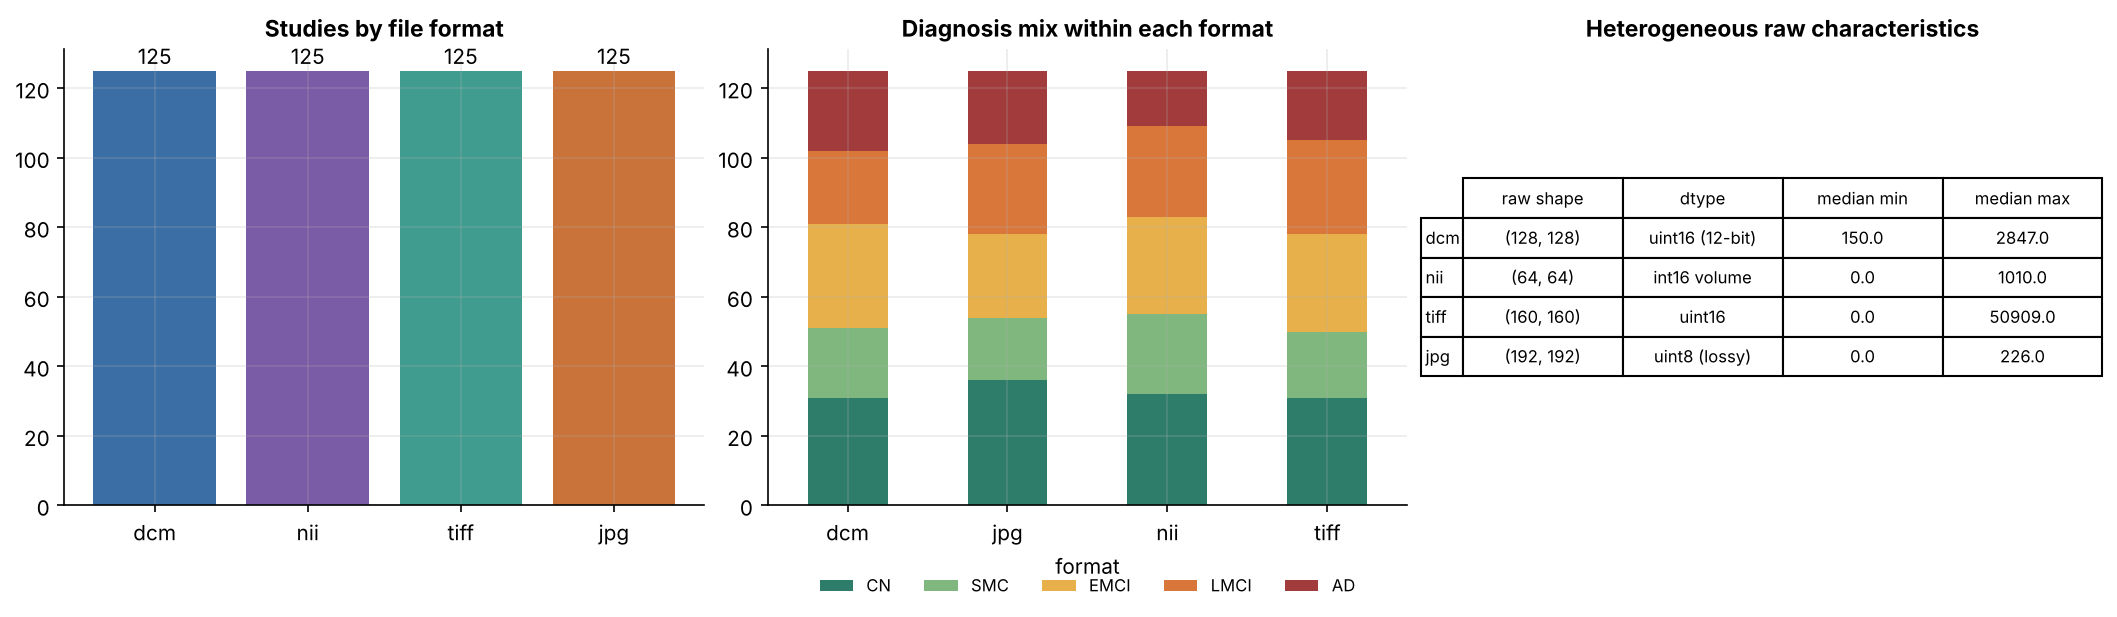

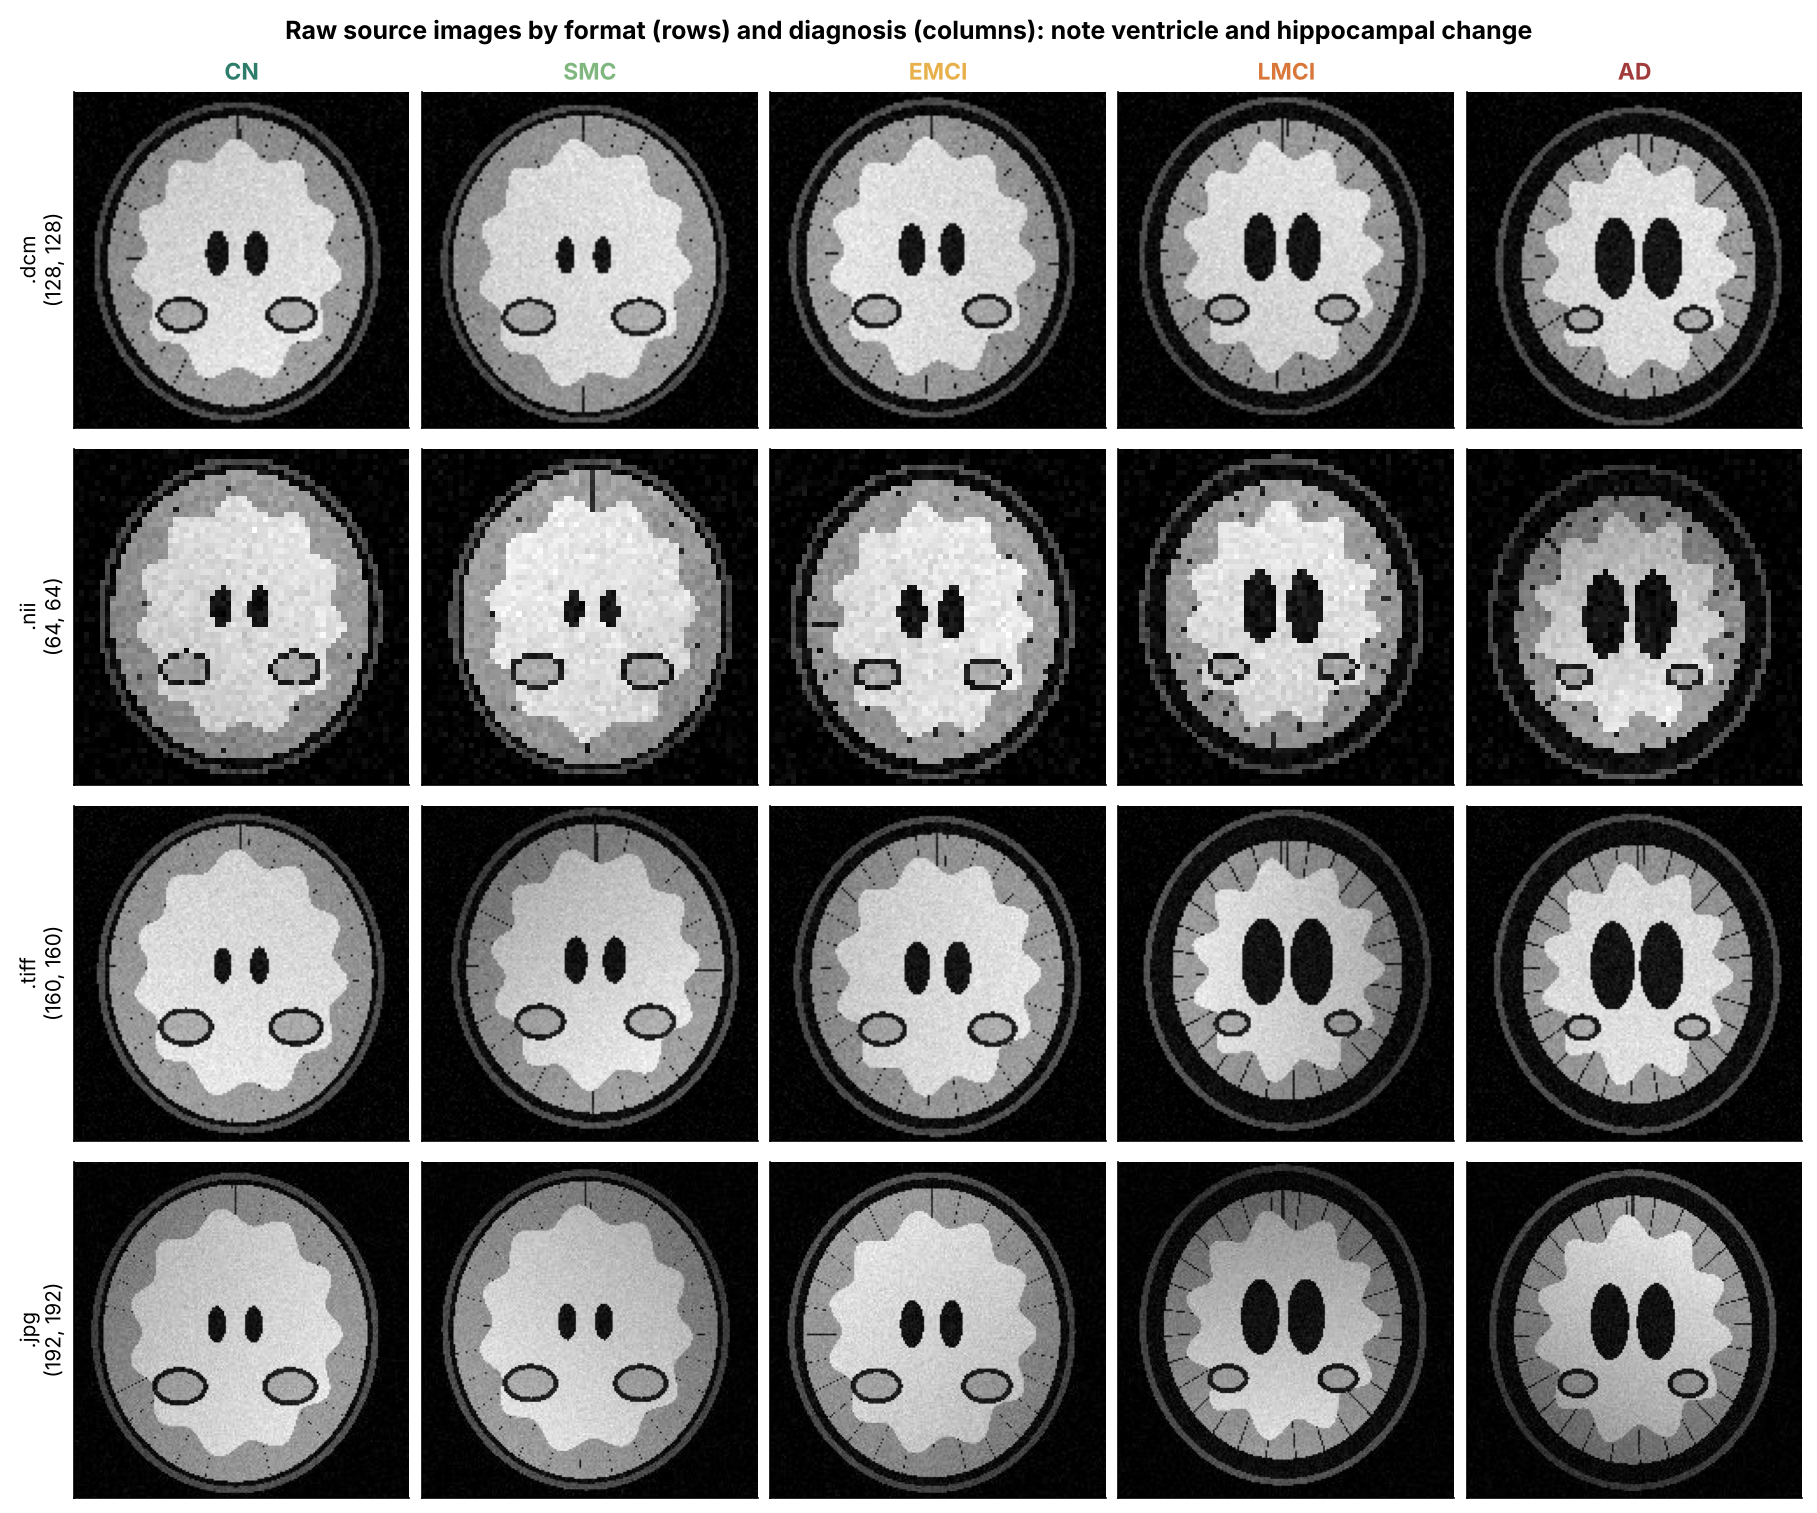

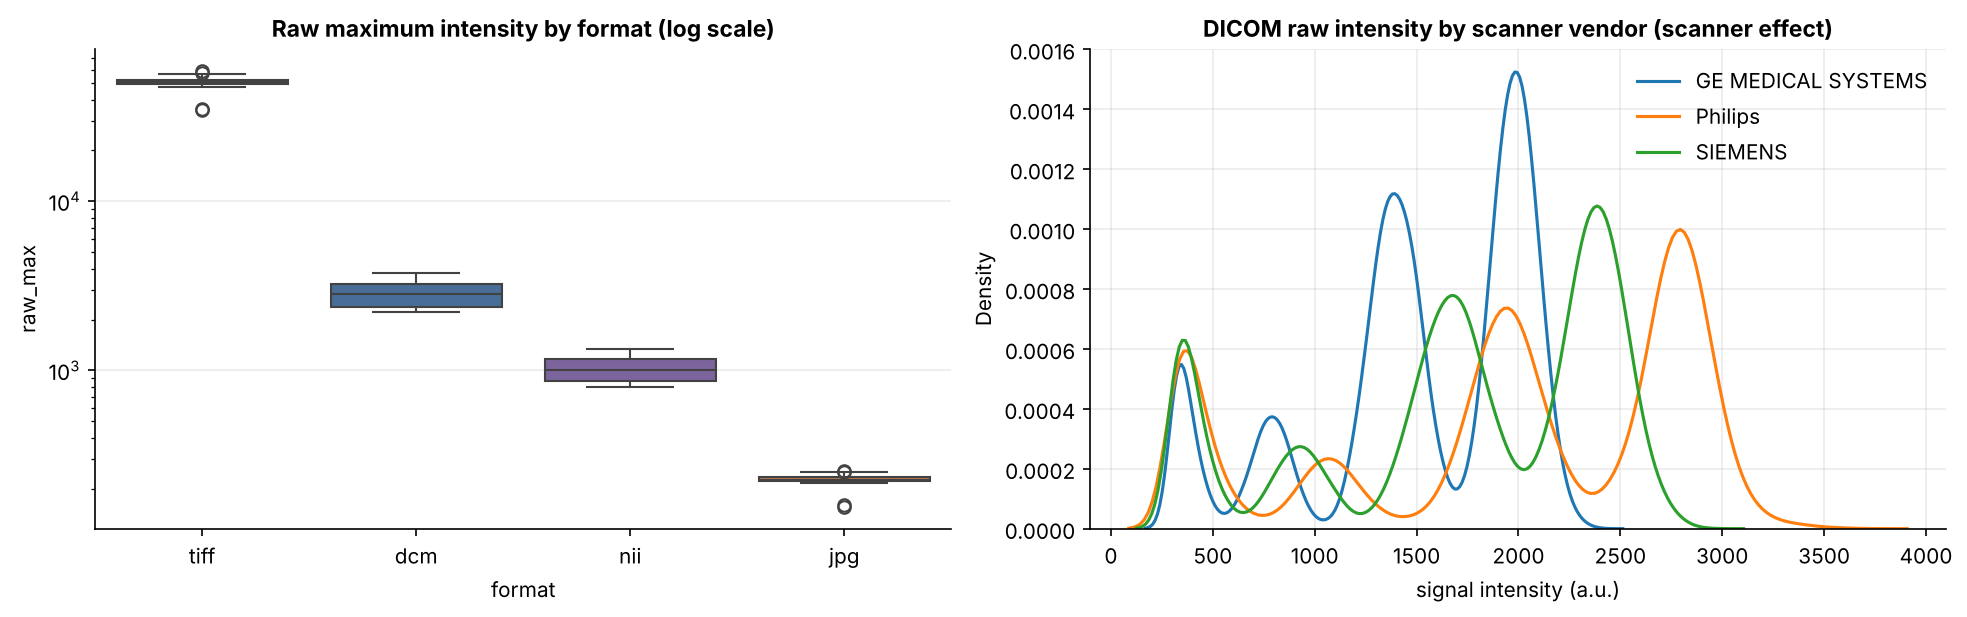

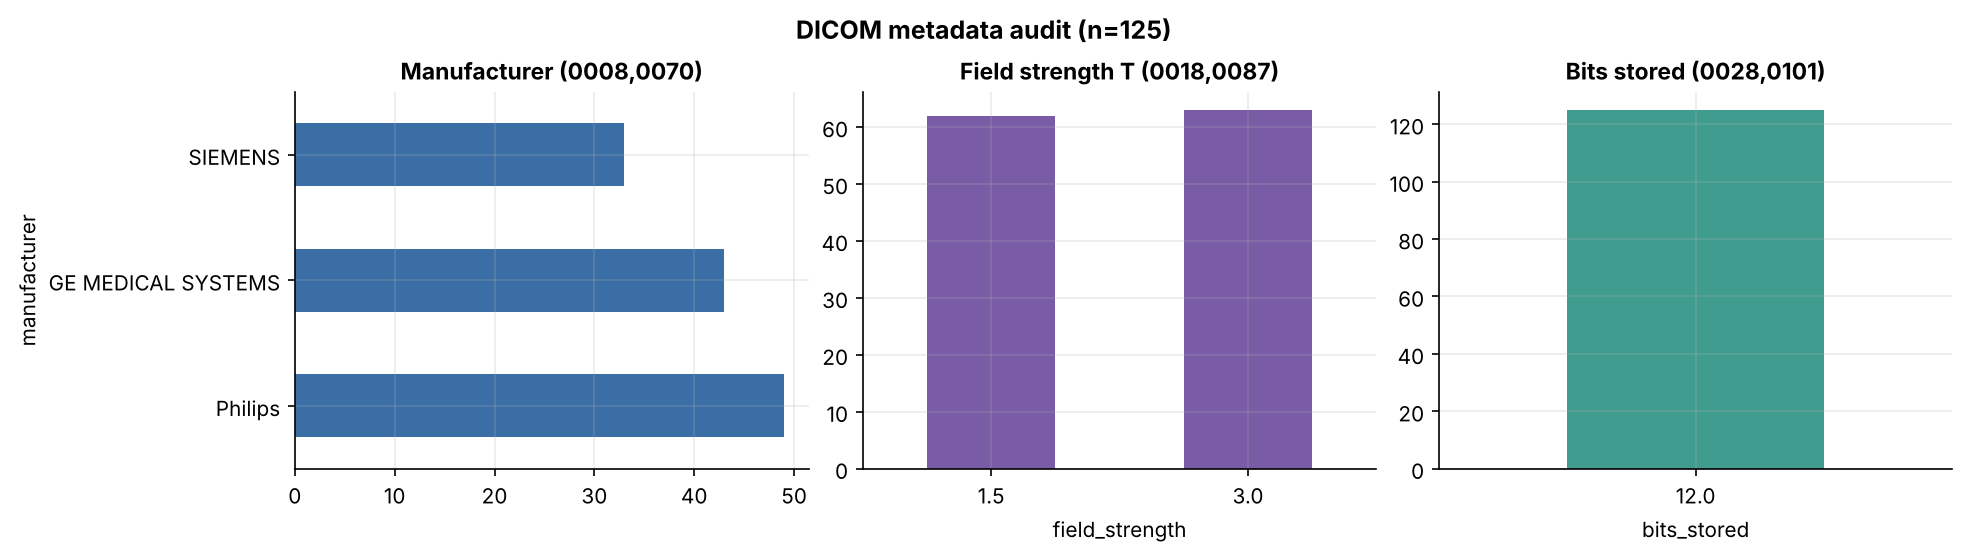

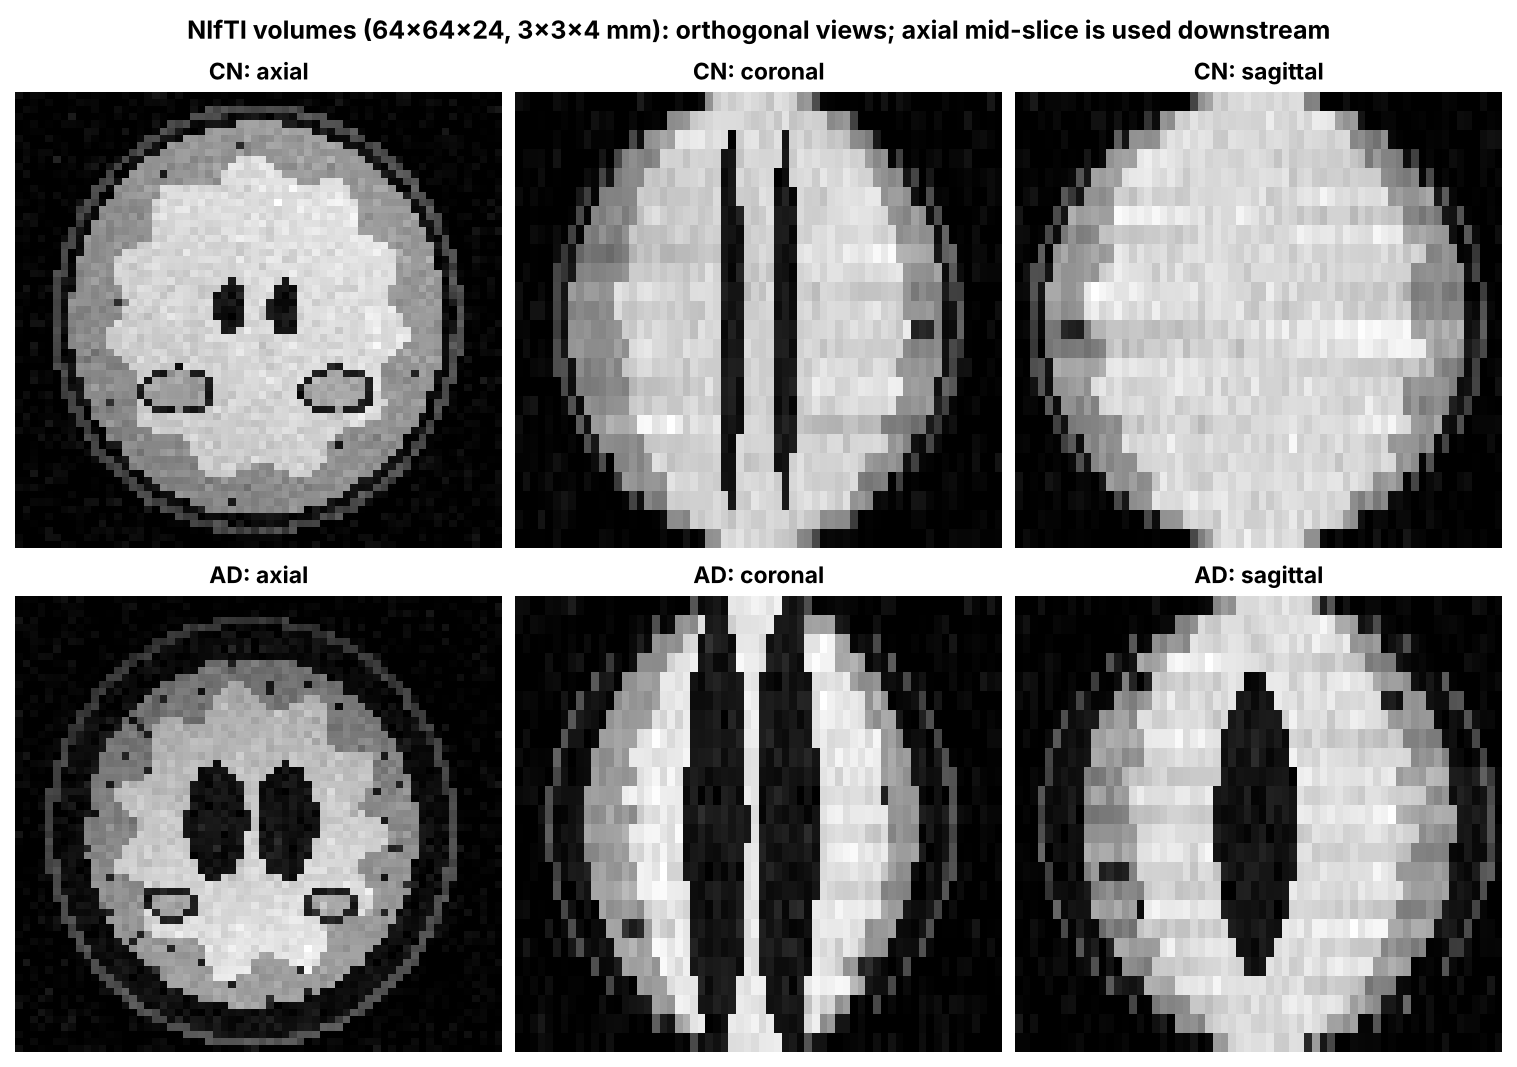

In [3]:
for n in ['01_img_format_inventory', '02_img_raw_samples_grid', '03_img_raw_intensity_heterogeneity', '04_img_dicom_header_audit', '05_img_nifti_orthoviews']: show(n)

## Automated QC and remediation

snr  noise_index  contrast  mask_fraction
format injected_defect                                             
dcm    flip_lr          5.851        0.064     0.706          0.508
       flip_ud          6.989        0.065     0.837          0.472
       low_contrast     6.349        0.060     0.673          0.548
       none             5.522        0.058     0.694          0.516
jpg    flip_ud          4.062        0.053     0.447          0.632
       high_noise       7.745        0.135     0.831          0.478
       low_contrast     4.100        0.046     0.503          0.620
       none             5.059        0.058     0.675          0.520
nii    none             5.416        0.056     0.705          0.515
tiff   flip_ud          6.424        0.056     0.754          0.498
       high_noise       4.464        0.114     0.529          0.611
       low_contrast     4.798        0.051     0.631          0.536
       none             5.057        0.052     0.674          0.523

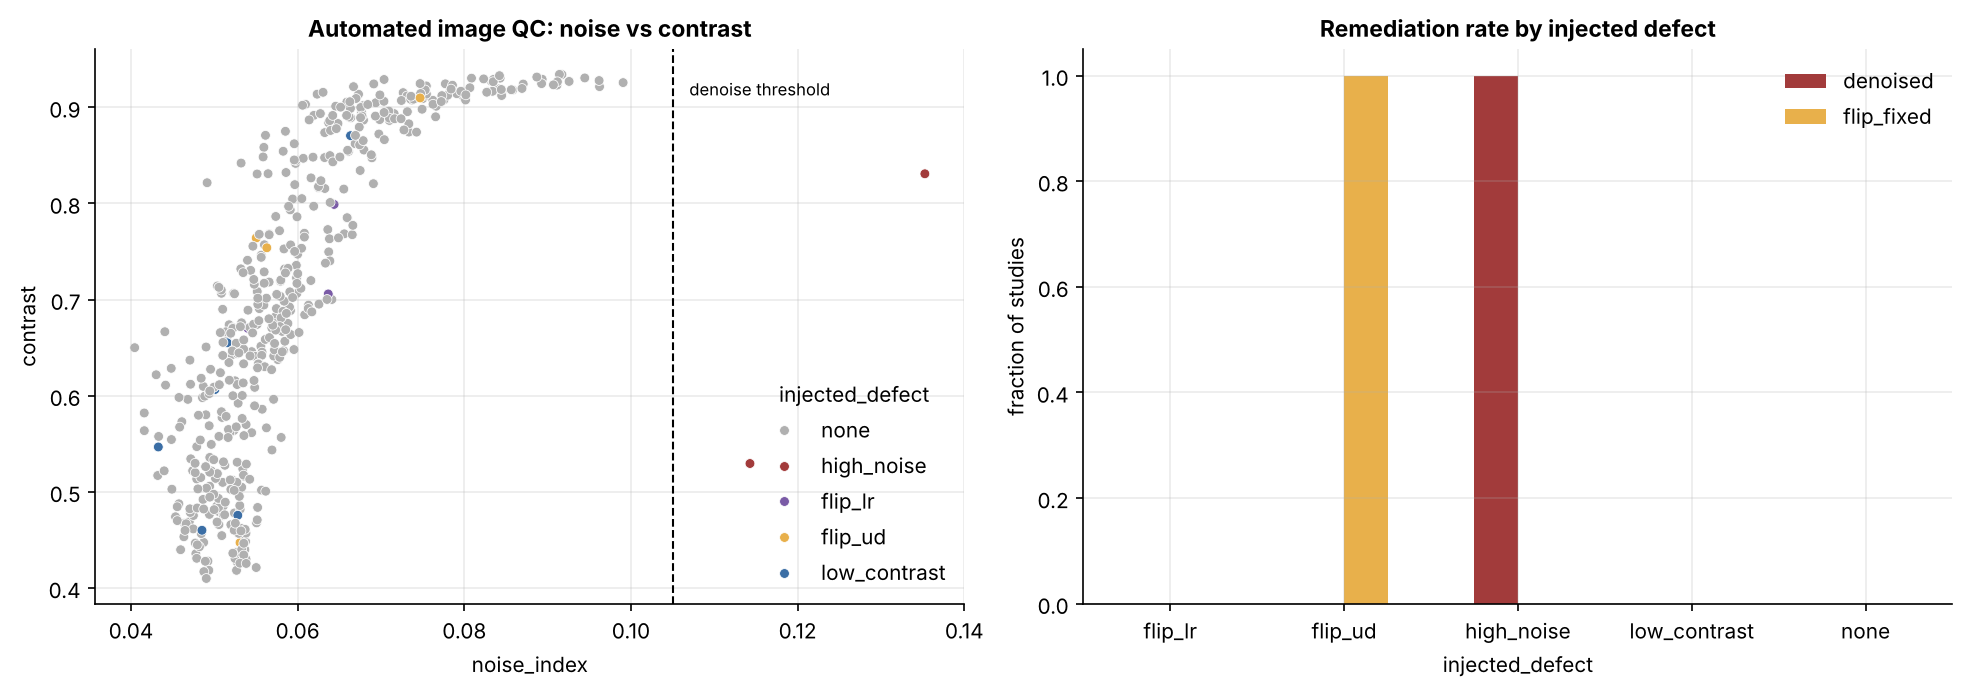

In [4]:
qc = pd.read_csv(ROOT / 'data/interim/imaging_qc.csv')
display(qc.groupby(['format', 'injected_defect'])[['snr', 'noise_index', 'contrast', 'mask_fraction']].median().round(3))
show('06_img_qc_defects')

## DICOM de-identification (PS3.15 Basic Profile subset) and PACS C-ECHO / C-STORE

In [5]:
import pydicom
from ad_mm.dicom.dicom_utils import deidentify
ds = pydicom.dcmread(ROOT / 'data/raw/imaging/dicom' / sorted((ROOT / 'data/raw/imaging/dicom').iterdir())[0].name)
print('before:', ds.PatientName, ds.get('PatientBirthDate'), ds.StudyDate)
ds2, log = deidentify(ds)
print('after :', ds2.PatientName, ds2.get('PatientBirthDate'), ds2.StudyDate, '| removed', log['removed'])
print(json.load(open(ROOT / 'reports/metrics/pacs_demo.json')))

before: Garcia^Drew 19480115 20250711
after : ANON None 20240917 | removed ['PatientName', 'PatientBirthDate']
{'c_echo_status': '0x0', 'c_store_statuses': ['0x0', '0x0', '0x0', '0x0', '0x0'], 'instances_received_by_scp': 5, 'round_trip_s': 0.289}
